In [34]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

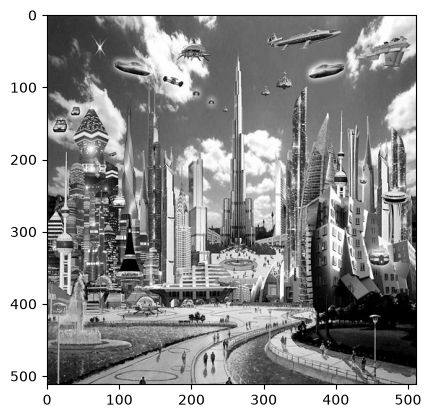

In [35]:
img = cv.imread('hw6.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap = 'gray')

In [36]:
def haarStep(mat):
    h, w = mat.shape
    
    row_trans = np.zeros((h, w))
    for i in range(h):
        row_trans[i, :w//2] = (mat[i, 0::2] + mat[i, 1::2]) / np.sqrt(2)
        row_trans[i, w//2:] = (mat[i, 0::2] - mat[i, 1::2]) / np.sqrt(2)
        
    col_trans = np.zeros((h, w))
    for j in range(w):
        col_trans[:h//2, j] = (row_trans[0::2, j] + row_trans[1::2, j]) / np.sqrt(2)
        col_trans[h//2:, j] = (row_trans[0::2, j] - row_trans[1::2, j]) / np.sqrt(2)
        
    return col_trans

In [37]:
def haarThreeStep(img):
    res = img.astype(float)
    h, w = res.shape
    
    res[:h, :w] = haarStep(res[:h, :w])
    
    plt.subplot(1,2,1)
    plt.imshow(res, cmap = 'gray')
    plt.title("Ступень 1")
    plt.subplot(1,2,2)
    plt.imshow(res[:h//2,:h//2], cmap = 'gray')
    plt.title("Ступень 1")
    plt.show()

    
    res[:h//2, :w//2] = haarStep(res[:h//2, :w//2])

    plt.subplot(1,2,1)
    plt.imshow(res, cmap = 'gray')
    plt.title("Ступень 2")
    plt.subplot(1,2,2)
    plt.imshow(res[:h//4,:h//4], cmap = 'gray')
    plt.title("Ступень 2")
    plt.show()

    
    res[:h//4, :w//4] = haarStep(res[:h//4, :w//4])

    plt.subplot(1,2,1)
    plt.imshow(res, cmap = 'gray')
    plt.title("Ступень 3")
    plt.subplot(1,2,2)
    plt.imshow(res[:h//8,:h//8], cmap = 'gray')
    plt.title("Ступень 3")
    plt.show()
    
    return res

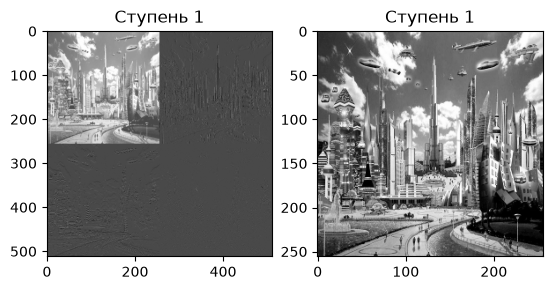

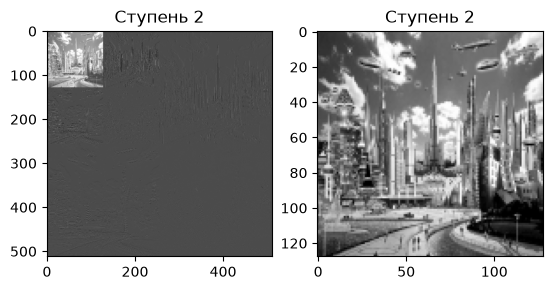

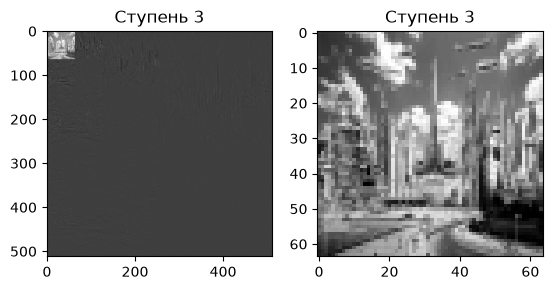

In [38]:
imgHaar = haarThreeStep(img)